# 0. Engine Fit Diagnostics
- Figure 1: PCIS influence screening (null calibration; masking of removed observations under the gene's own dispersion).
- Figure 2: empirical-Bayes dispersion model (trend, bias, intercept and slope shrinkage).
- Figure S1: individual-fit convergence across nz (pooling threshold).
- Producers (run once, cache-first): `notebookscripts/EngineDiagnostics/pcis_case_study.py`, `notebookscripts/EngineDiagnostics/low_nz_convergence.py`; outputs in `config.ENGINE_DIAG_DIR`.

In [7]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import json
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import f as f_dist

os.environ["NM_PIPELINE"] = "p0"
sys.path.insert(0, str(Path.cwd().parents[1]))
import MixedEffectsModeling.config as config
from MixedEffectsModeling.core.dispersion_trend import load_trend
from viz_style import apply_style
apply_style()

FIG = config.ENGINE_DIAG_DIR / "Figures"
FIG.mkdir(parents=True, exist_ok=True)
CUT = config.FIT_PARAMS["pcis_cut"]
BLUE, ORANGE, RED = "#2b5c8f", "#e07a5f", "#d62828"

def grid_on(ax):
    ax.grid(True, which="major", color="0.88", lw=0.7)
    ax.set_axisbelow(True)

def panel(ax, s):
    ax.text(-0.12, 1.02, s, transform=ax.transAxes, fontsize=17, fontweight="bold", va="bottom")

LEG = dict(frameon=False, fontsize=11)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Figure 1. PCIS influence screening
PCIS (Eq. 13) has the form of Cook's distance but scales the residual by the trend dispersion $\alpha^{\mathrm{trend}}$. Cook's distance uses the gene's own fitted, covariate-dependent dispersion $\hat\alpha_i(x_j)$; because that dispersion is regressed on covariates, an extreme count inflates it at its own position and the count falls inside the gene's own predictive distribution (masking). PCIS is used as an empirical safety screen, not a test.

Panel order follows the Methods text: a Cook's distance misses the removed observations; b-d why (masking by the gene's own dispersion); e how the cut was set.

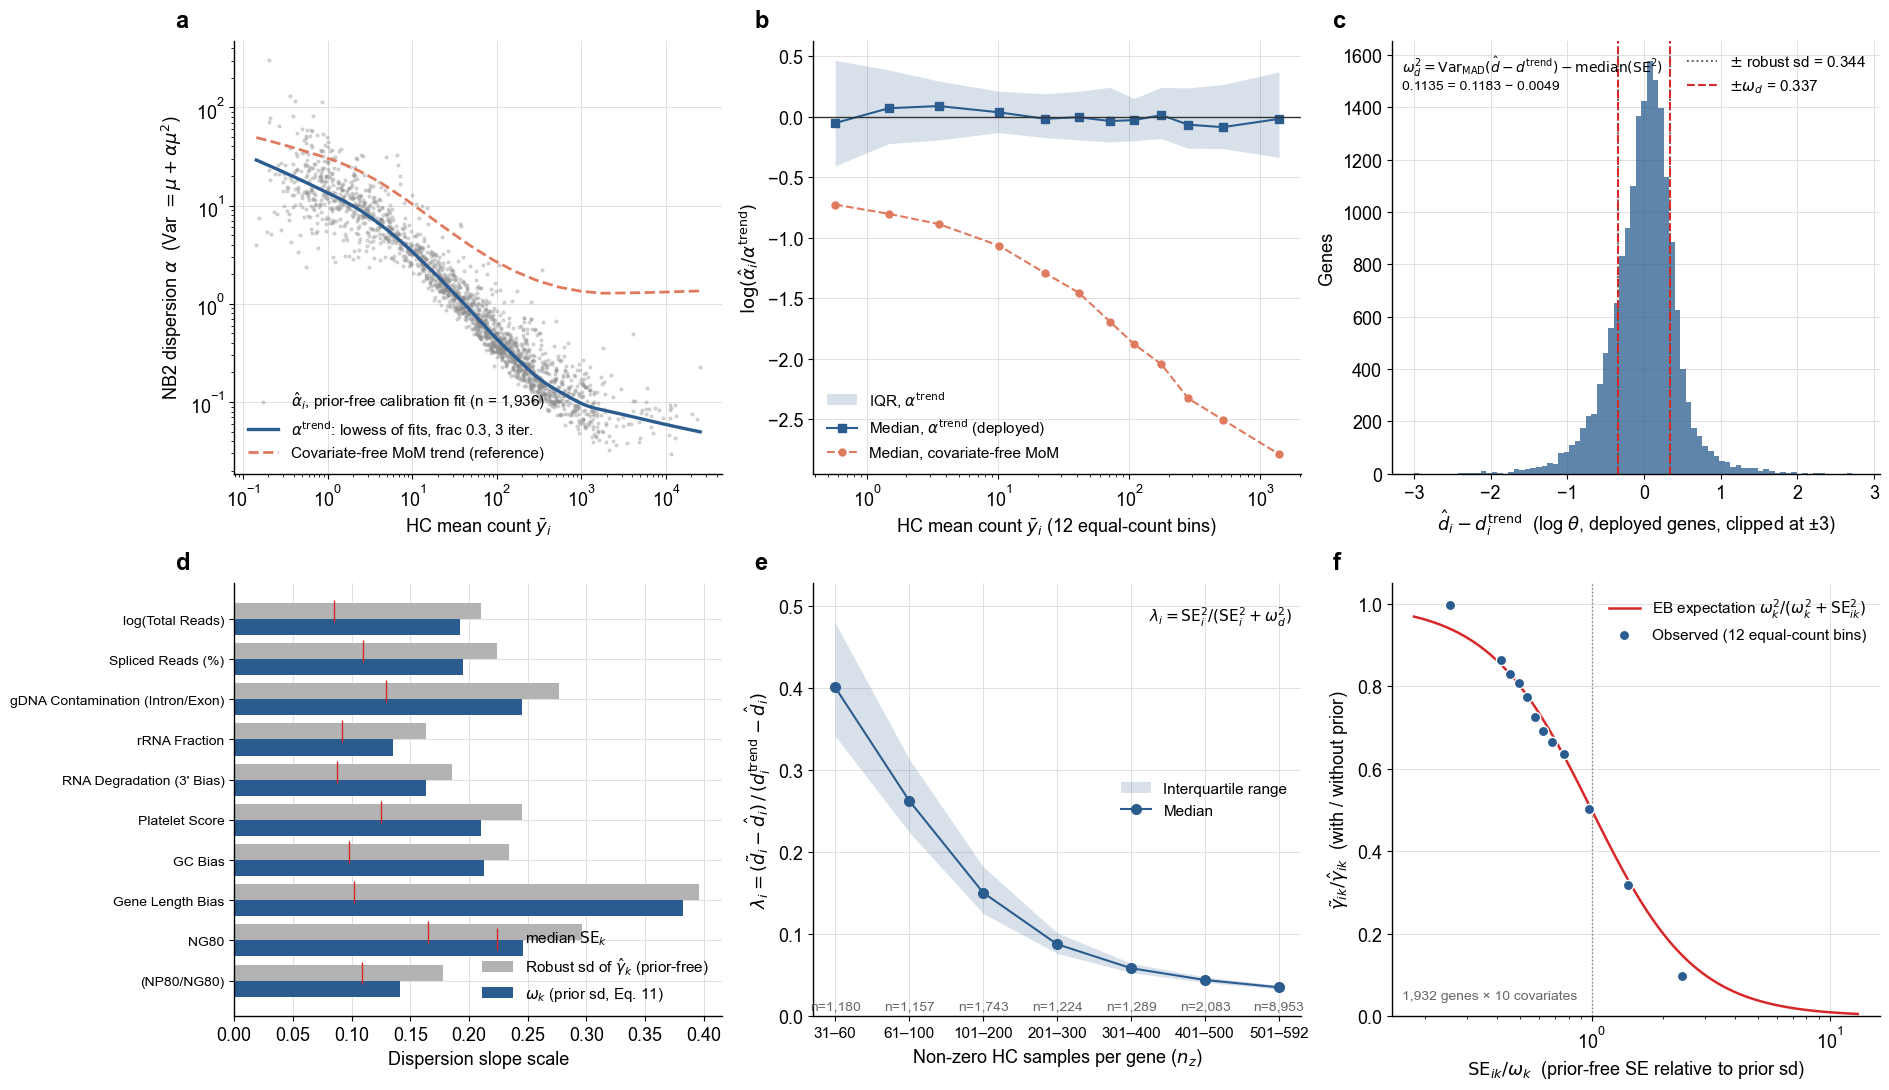

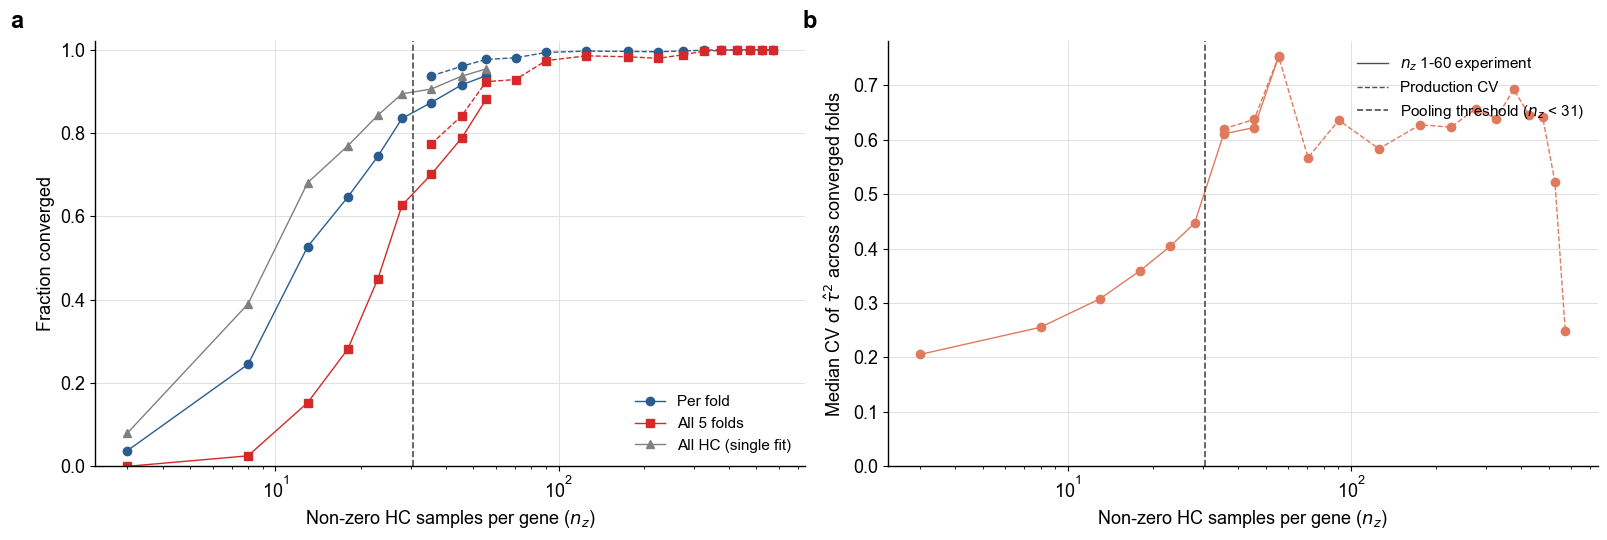

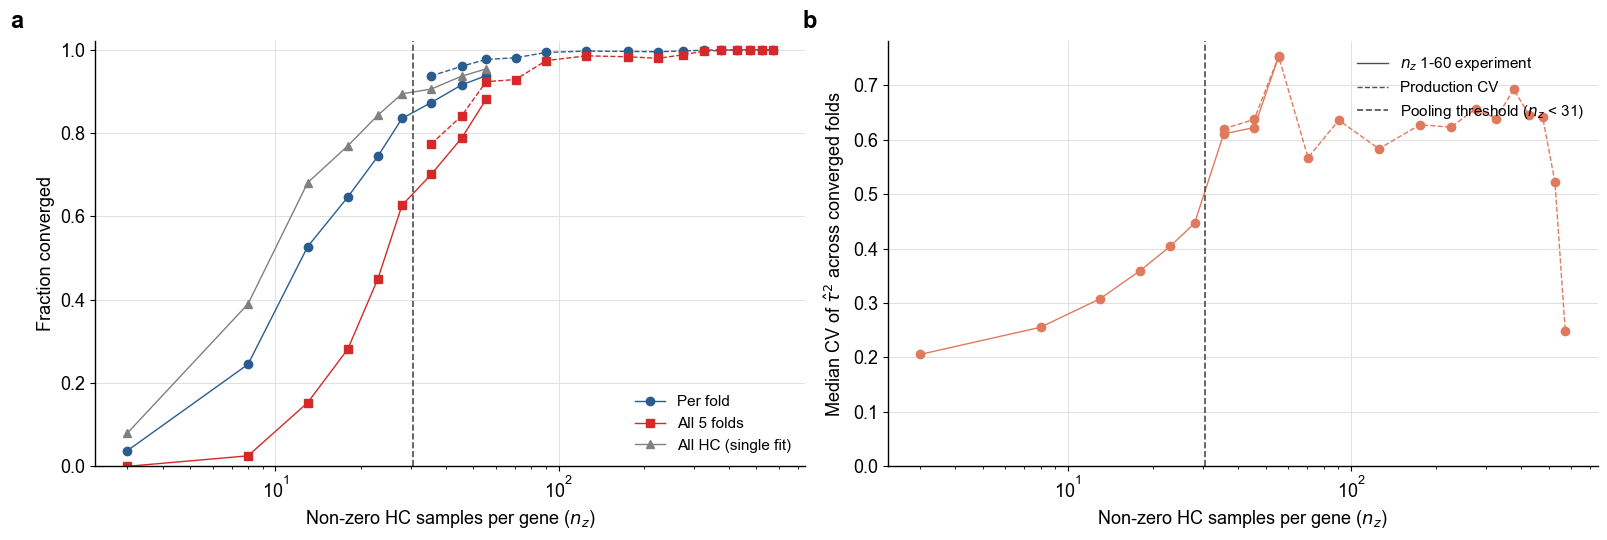

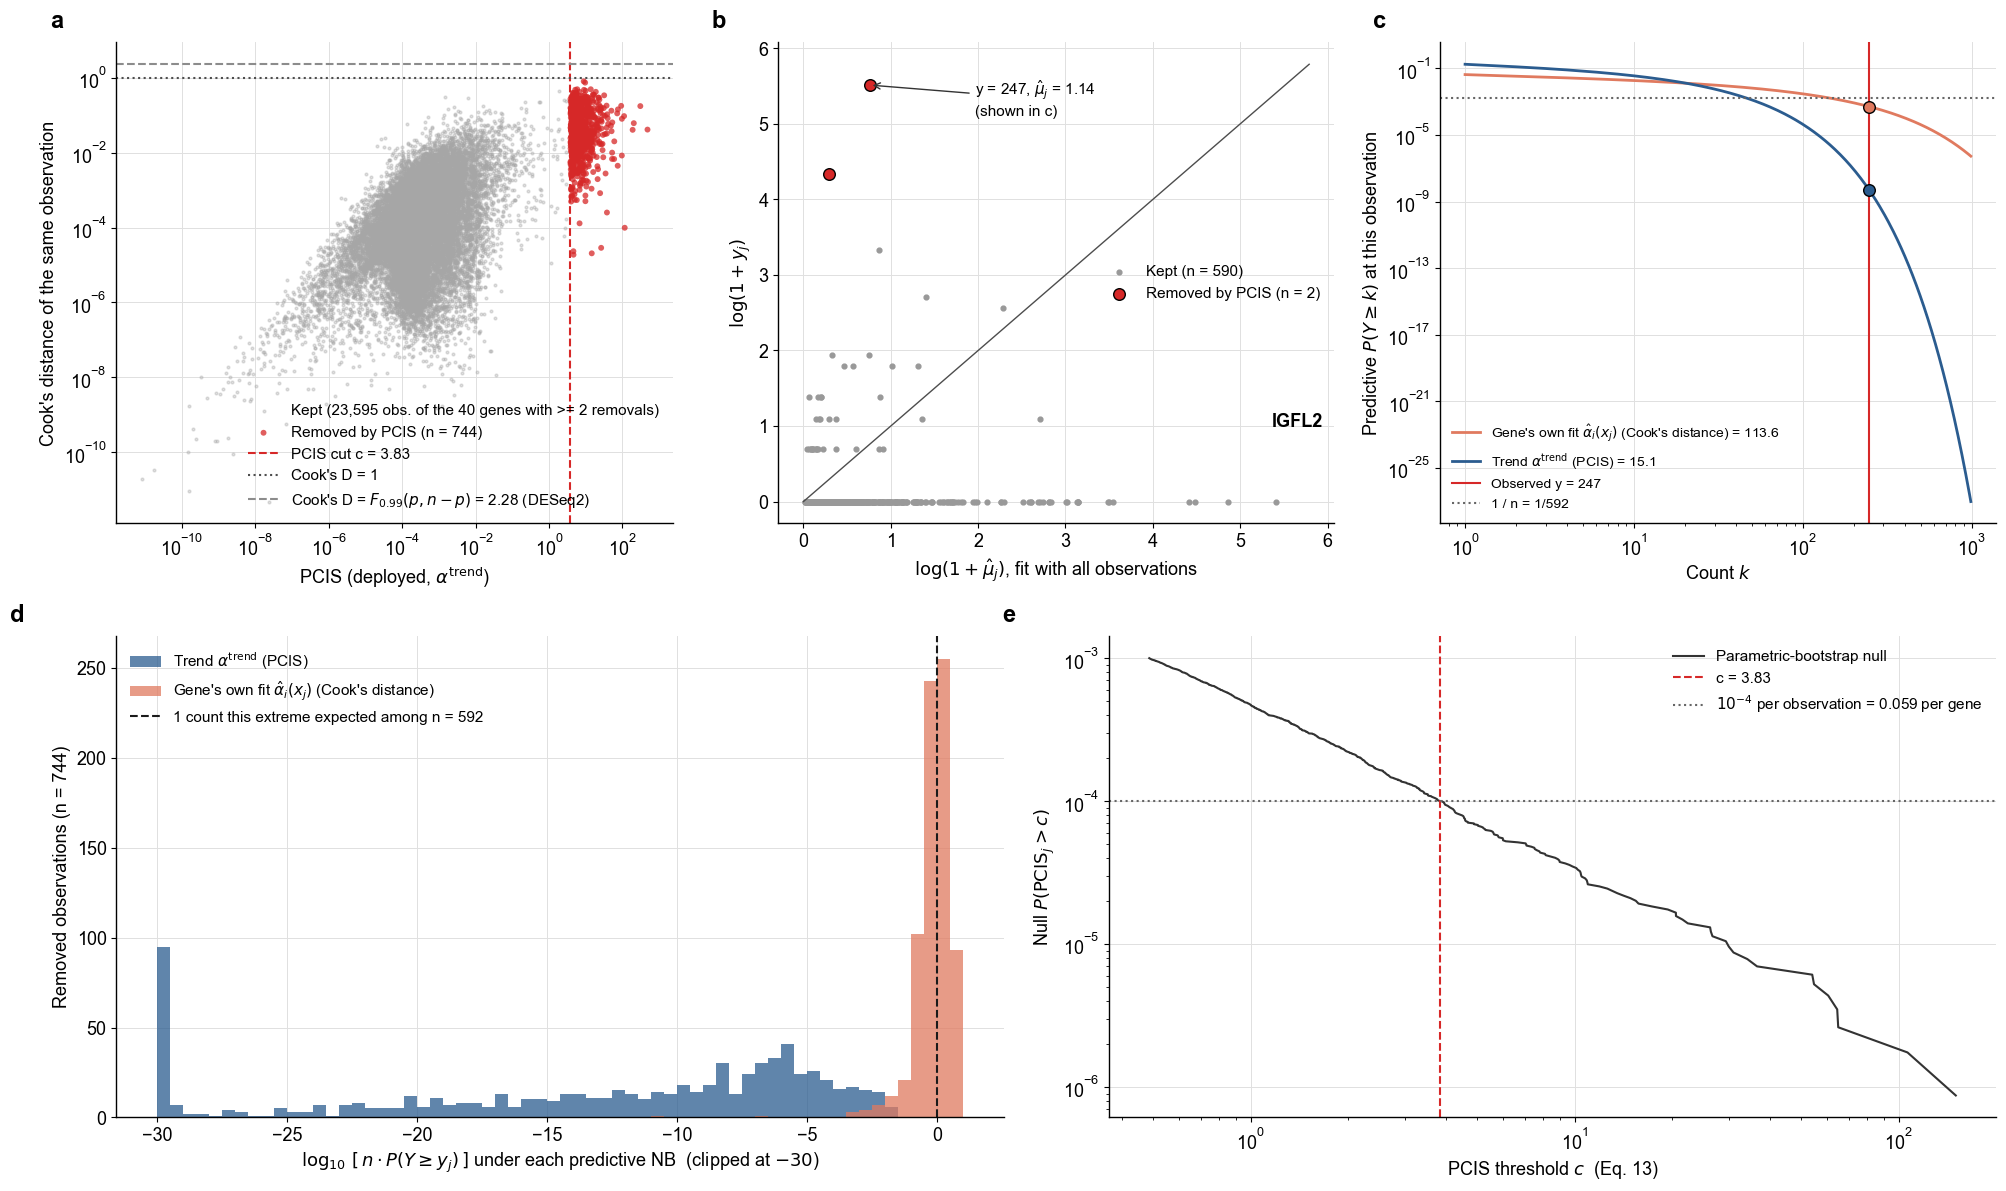

Figure 1. PCIS influence screening
  a  PCIS vs Cook's distance per observation: removed (all genes) and kept (genes with >= 2 removals)
  b  Example gene IGFL2: observed vs fitted counts, observations removed by PCIS in red
  c  Same gene, largest removed count: predictive tail under the gene's own dispersion (Cook's distance) vs the trend dispersion (PCIS)
  d  All removed observations: expected number of counts this extreme among n under each predictive NB
  e  Null PCIS (parametric bootstrap): false-removal rate vs threshold; cut at 1e-4 per observation

removed observations 744: Cook's D > 1 0, Cook's D > F_0.99 (DESeq2, 2.28) 0
n*P(Y>=y): own-fit median 0.90, trend median 3.4e-11
own / trend dispersion at the removed observation: median 22.4x


In [8]:
from scipy.stats import nbinom

null = pd.read_csv(config.PCIS_CAL_DIR / "null_pcis_top50_raw.csv.gz")
null = null[np.isfinite(null.pcis)]
n_obs = int(null.n_obs.iloc[0])
pcis = np.sort(null.pcis.values)[::-1]
rate = np.arange(1, len(pcis) + 1) / (null.groupby(["gene", "rep"]).ngroups * n_obs)
keep = rate <= 1e-3

def nb_sf(y, mu, a):
    size = 1 / np.asarray(a, float)
    return nbinom.sf(np.asarray(y) - 1, size, size / (size + np.asarray(mu, float)))

gcase = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_gene.csv")
obs = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_obs.csv.gz").merge(gcase[["gene", "symbol", "trend_alpha"]], on="gene")
rem = obs[obs.removed].copy()
P_FIX = 1 + len(config.COVARIATES)
D_DESEQ2 = f_dist.ppf(0.99, P_FIX, n_obs - P_FIX)
rem["np_own"] = n_obs * nb_sf(rem.y, rem.mu, rem.alpha_own)
rem["np_trend"] = n_obs * nb_sf(rem.y, rem.mu, rem.trend_alpha)
gcase["inflation"] = gcase.alpha_own_with / gcase.alpha_own_without
ex_gene = gcase[gcase.n_drop >= 2].sort_values("inflation").iloc[-1]
o = obs[obs.gene == ex_gene.gene]
r = o[o.removed]
ex = r.sort_values("y").iloc[-1]
ex_name = ex.symbol if isinstance(ex.symbol, str) and not ex.symbol.startswith("ENSG") else ex.gene.split(".")[0]
OWN_LAB = r"Gene's own fit $\hat{\alpha}_i(x_j)$ (Cook's distance)"
TREND_LAB = r"Trend $\alpha^{\mathrm{trend}}$ (PCIS)"

fig, axes = plt.subplot_mosaic([["a", "a", "b", "b", "c", "c"], ["d", "d", "d", "e", "e", "e"]], figsize=(20, 12))
ax = axes["a"]
full_genes = obs.groupby("gene").size().loc[lambda v: v == n_obs].index
kept = obs[obs.gene.isin(full_genes) & ~obs.removed]
ax.scatter(kept.pcis_trend, kept.cooks, s=4, color="0.65", alpha=0.35, rasterized=True,
           label=f"Kept ({len(kept):,} obs. of the {len(full_genes)} genes with >= 2 removals)")
ax.scatter(rem.pcis_trend, rem.cooks, s=18, color=RED, alpha=0.75, edgecolor="none", label=f"Removed by PCIS (n = {len(rem)})")
ax.axvline(CUT, color=RED, ls="--", lw=1.5, label=f"PCIS cut c = {CUT:.2f}")
ax.axhline(1, color="0.3", ls=":", lw=1.5, label="Cook's D = 1")
ax.axhline(D_DESEQ2, color="0.55", ls="--", lw=1.5, label=r"Cook's D = $F_{0.99}(p, n-p)$" + f" = {D_DESEQ2:.2f} (DESeq2)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"PCIS (deployed, $\alpha^{\mathrm{trend}}$)"); ax.set_ylabel("Cook's distance of the same observation")
ax.legend(**LEG, loc="lower right"); grid_on(ax); panel(ax, "a")

ax = axes["b"]
ax.scatter(np.log1p(o.mu), np.log1p(o.y), s=12, color="0.6", label=f"Kept (n = {len(o) - len(r)})")
ax.scatter(np.log1p(r.mu), np.log1p(r.y), s=70, color=RED, edgecolor="black", zorder=3, label=f"Removed by PCIS (n = {len(r)})")
lim = [0, max(np.log1p(o.y).max(), np.log1p(o.mu).max()) * 1.05]
ax.plot(lim, lim, color="0.3", lw=1)
ax.annotate(f"y = {int(ex.y)}, " + r"$\hat{\mu}_j$" + f" = {ex.mu:.2f}\n(shown in c)", xy=(np.log1p(ex.mu), np.log1p(ex.y)),
            xytext=(np.log1p(ex.mu) + 1.2, np.log1p(ex.y) - 0.4), fontsize=11, arrowprops=dict(arrowstyle="->", color="0.2"))
ax.set_xlabel(r"$\log(1+\hat{\mu}_j)$, fit with all observations"); ax.set_ylabel(r"$\log(1+y_j)$")
ax.text(0.98, 0.2, ex_name, transform=ax.transAxes, ha="right", fontsize=13, fontweight="bold")
ax.legend(**LEG, loc="center right"); grid_on(ax); panel(ax, "b")

ax = axes["c"]
k = np.unique(np.round(np.geomspace(1, ex.y * 4, 400)).astype(int))
ax.loglog(k, nb_sf(k, ex.mu, ex.alpha_own), color=ORANGE, lw=2, label=OWN_LAB + f" = {ex.alpha_own:.1f}")
ax.loglog(k, nb_sf(k, ex.mu, ex.trend_alpha), color=BLUE, lw=2, label=TREND_LAB + f" = {ex.trend_alpha:.1f}")
ax.axvline(ex.y, color=RED, lw=1.5, label=f"Observed y = {int(ex.y)}")
ax.axhline(1 / n_obs, color="0.4", ls=":", lw=1.5, label=f"1 / n = 1/{n_obs}")
for a, c in [(ex.alpha_own, ORANGE), (ex.trend_alpha, BLUE)]:
    ax.scatter([ex.y], [nb_sf(ex.y, ex.mu, a)], s=70, color=c, edgecolor="black", zorder=3)
ax.set_xlabel(r"Count $k$"); ax.set_ylabel(r"Predictive $P(Y \geq k)$ at this observation")
ax.legend(frameon=False, fontsize=10, loc="lower left"); grid_on(ax); panel(ax, "c")

ax = axes["d"]
bins = np.linspace(-30, 1, 63)
ax.hist(np.log10(rem.np_trend).clip(bins[0], None), bins=bins, color=BLUE, alpha=0.75, label=TREND_LAB)
ax.hist(np.log10(rem.np_own).clip(bins[0], None), bins=bins, color=ORANGE, alpha=0.75, label=OWN_LAB)
ax.axvline(0, color="0.1", ls="--", lw=1.5, label=f"1 count this extreme expected among n = {n_obs}")
ax.set_xlabel(r"$\log_{10}\,[\,n \cdot P(Y \geq y_j)\,]$ under each predictive NB  (clipped at $-30$)")
ax.set_ylabel(f"Removed observations (n = {len(rem)})")
ax.legend(**LEG, loc="upper left"); grid_on(ax); panel(ax, "d")

ax = axes["e"]
ax.loglog(pcis[keep], rate[keep], color="0.2", lw=1.5, label="Parametric-bootstrap null")
ax.axvline(CUT, color=RED, ls="--", lw=1.5, label=f"c = {CUT:.2f}")
ax.axhline(1e-4, color="0.4", ls=":", lw=1.5, label=r"$10^{-4}$ per observation" + f" = {1e-4 * n_obs:.3f} per gene")
ax.set_xlabel(r"PCIS threshold $c$  (Eq. 13)"); ax.set_ylabel(r"Null $P(\mathrm{PCIS}_j > c)$")
ax.legend(**LEG); grid_on(ax); panel(ax, "e")

plt.tight_layout()
plt.savefig(FIG / "fig1_pcis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 1. PCIS influence screening")
print("  a  PCIS vs Cook's distance per observation: removed (all genes) and kept (genes with >= 2 removals)")
print(f"  b  Example gene {ex_name}: observed vs fitted counts, observations removed by PCIS in red")
print(f"  c  Same gene, largest removed count: predictive tail under the gene's own dispersion (Cook's distance) vs the trend dispersion (PCIS)")
print("  d  All removed observations: expected number of counts this extreme among n under each predictive NB")
print("  e  Null PCIS (parametric bootstrap): false-removal rate vs threshold; cut at 1e-4 per observation")
print(f"\nremoved observations {len(rem)}: Cook's D > 1 {(rem.cooks > 1).sum()}, Cook's D > F_0.99 (DESeq2, {D_DESEQ2:.2f}) {(rem.cooks > D_DESEQ2).sum()}")
print(f"n*P(Y>=y): own-fit median {rem.np_own.median():.2f}, trend median {rem.np_trend.median():.1e}")
print(f"own / trend dispersion at the removed observation: median {np.median(rem.alpha_own / rem.trend_alpha):.1f}x")

## Figure 2. Empirical-Bayes dispersion model
Notation follows the Methods: NB2 $\mathrm{Var}(y)=\mu+\alpha\mu^2$, $\theta = 1/\alpha$, dispersion intercept $d_i = \log\theta_i$, slopes $\gamma_{ik}$. Supersedes the training-time panel `EngineState/Figures/dispersion_trend.png`.
- **a** Prior-free calibration fits (1,936 genes) and the lowess trend $\alpha^{\mathrm{trend}}$ that centres the intercept prior (Eq. 12) and scales the PCIS residual (Eq. 13). Dashed: covariate-free method-of-moments trend on raw HC counts (reference).
- **b** Bias of each trend against the conditional fits by expression bin: the fitted trend stays near 0, the covariate-free MoM trend overstates dispersion increasingly with expression, which is why the trend is built from covariate-conditional fits.
- **c** Intercept prior scale (Eq. 12): $\omega_d^2$ = robust (MAD) variance of $\hat d_i - d_i^{\mathrm{trend}}$ over deployed genes minus the median $\mathrm{SE}_i^2$.
- **d** Slope prior scales (Eq. 11): per covariate, the robust spread of prior-free slopes $\hat\gamma_{k}$ splits into estimation noise (median $\mathrm{SE}_k$) and true between-gene spread $\omega_k$.
- **e** Eq. 12 moves $\hat d_i$ toward $d_i^{\mathrm{trend}}$ by $\lambda_i = \mathrm{SE}_i^2/(\mathrm{SE}_i^2+\omega_d^2)$; the move is large only for genes with few non-zero samples.
- **f** Slopes fitted with the prior vs the same genes without it, against the normal-normal expectation $\omega_k^2/(\omega_k^2+\mathrm{SE}_{ik}^2)$ (a check, not an identity: the deployed slopes come from a joint glmmTMB fit).

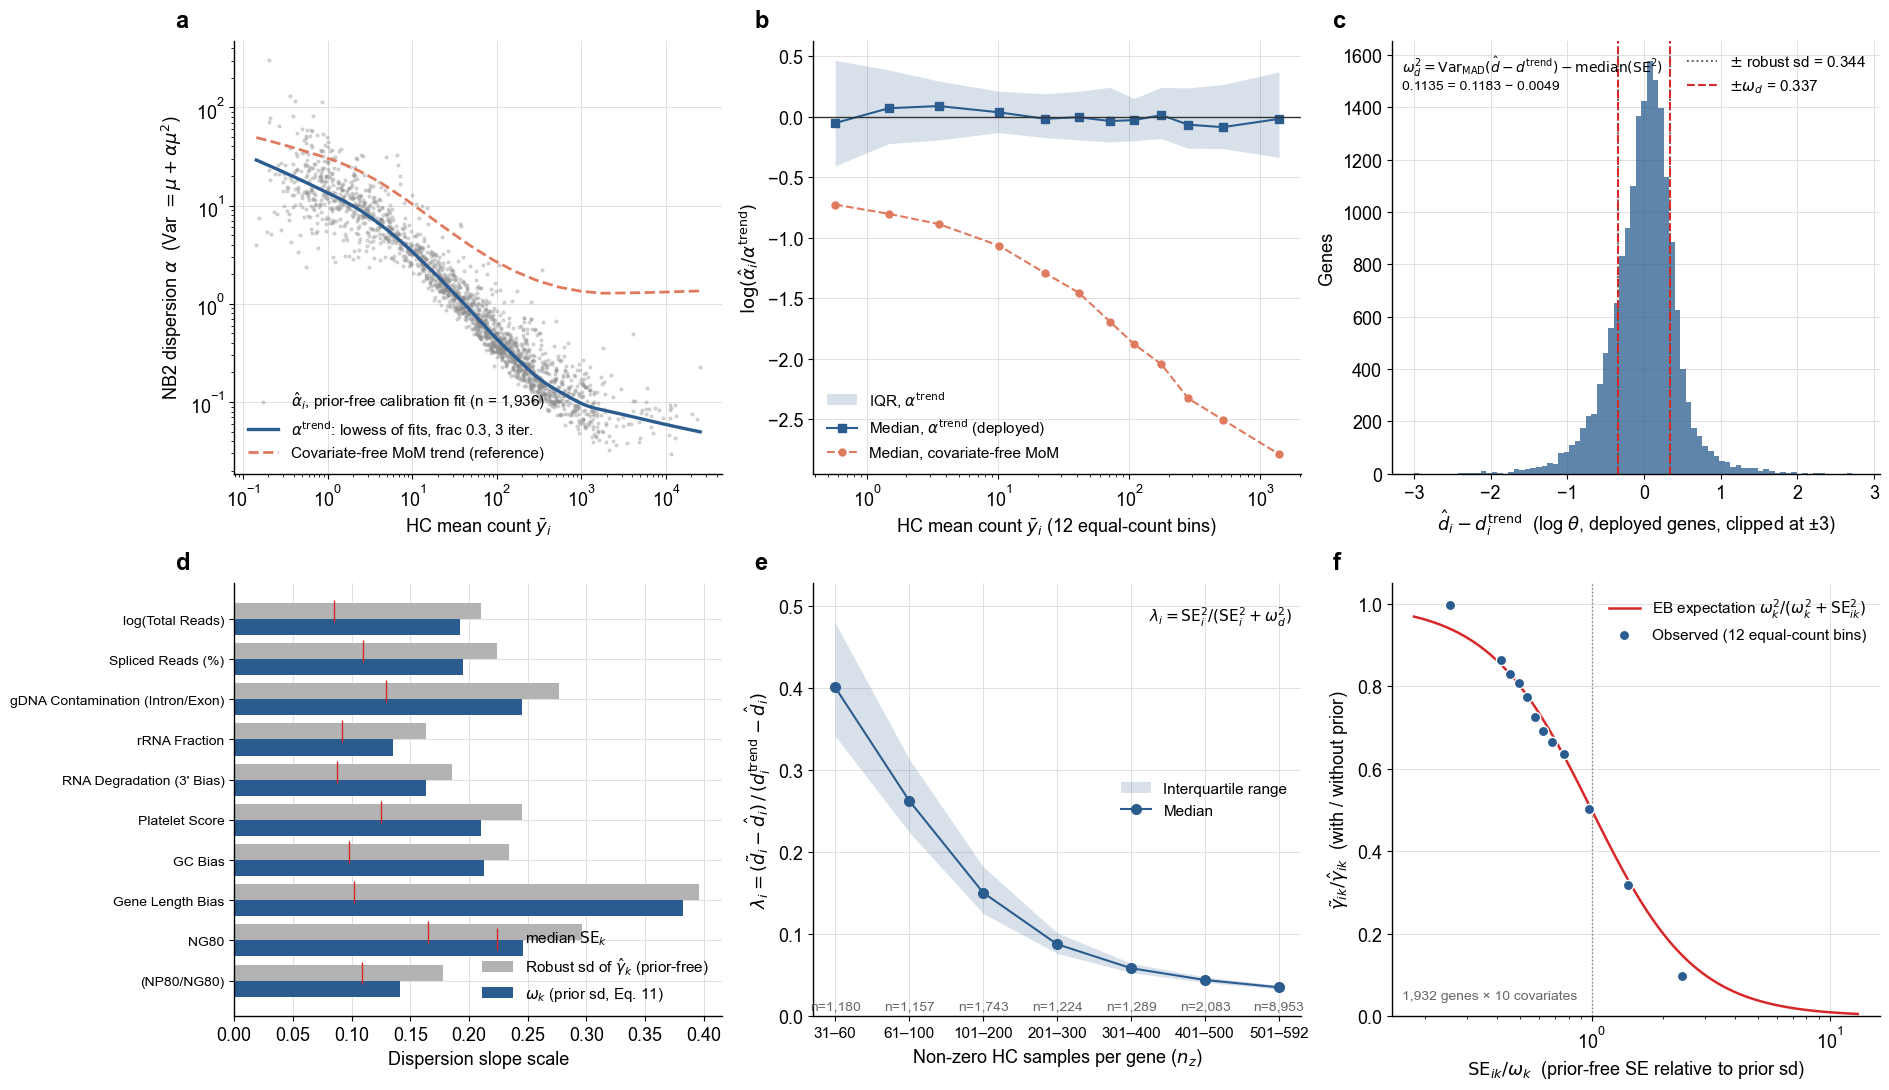

Figure 2. Empirical-Bayes dispersion model
  a  Mean-dispersion relationship: prior-free calibration fits, lowess trend, covariate-free MoM reference
  b  Trend bias by expression bin (fitted trend vs covariate-free MoM)
  c  Intercept prior scale omega_d: deviation of d_hat from the trend, Eq. 12
  d  Slope prior scales omega_k per covariate: total spread vs estimation noise, Eq. 11
  e  Intercept shrink fraction lambda_i by non-zero HC samples n_z
  f  Slope shrinkage with vs without prior against the EB expectation
b: fitted trend |median| max 0.087; MoM trend median range -2.79 to -0.73
c: omega_d^2 0.1135 vs MAD var 0.1183 - median SE^2 0.0049 = 0.1135


,omega_k,robust_sd_prior_free,median_SE
log(Total Reads),0.192,0.210,0.085
Spliced Reads (%),0.195,0.224,0.110
gDNA Contamination (Intron/Exon),0.245,0.277,0.129
rRNA Fraction,0.135,0.163,0.091
RNA Degradation (3' Bias),0.163,0.185,0.087
Platelet Score,0.210,0.245,0.125
GC Bias,0.213,0.234,0.098
Gene Length Bias,0.383,0.396,0.102
NG80,0.246,0.296,0.165
(NP80/NG80),0.141,0.178,0.109


,lambda_median,lambda_q25,lambda_q75,SE_median,n
nz,,,,,
"(30, 60]",0.401,0.342,0.480,0.276,1180
"(60, 100]",0.263,0.225,0.314,0.201,1157
"(100, 200]",0.151,0.125,0.183,0.142,1743
"(200, 300]",0.088,0.077,0.102,0.105,1224
"(300, 400]",0.059,0.053,0.065,0.084,1289
"(400, 500]",0.044,0.041,0.048,0.072,2083
"(500, 592]",0.035,0.033,0.038,0.064,8953


,x,ratio,n
x,,,
"(0.178, 0.387]",0.254,0.997,1610.0
"(0.387, 0.436]",0.415,0.863,1610.0
"(0.436, 0.476]",0.455,0.831,1610.0
"(0.476, 0.516]",0.497,0.807,1610.0
"(0.516, 0.554]",0.534,0.774,1610.0
"(0.554, 0.601]",0.577,0.725,1610.0
"(0.601, 0.65]",0.624,0.692,1610.0
"(0.65, 0.714]",0.679,0.664,1610.0
"(0.714, 0.844]",0.764,0.635,1610.0


In [9]:
from MixedEffectsModeling.core.dispersion_trend import build_trend, save_trend

CAL_MEAN = config.ENGINE_DIAG_DIR / "calib_gene_mean.csv"
MOM_TREND = config.ENGINE_DIAG_DIR / "mom_trend.json"
calib = pd.read_csv(config.ENGINE_DIR / "calib_fits.csv")
if not (CAL_MEAN.is_file() and MOM_TREND.is_file()):
    import scanpy as sc
    hc = pd.read_csv(config.ZSCORES_DIR / "hc_meta.csv")["sample"].values
    ad = sc.read_h5ad(config.H5AD_PATH, backed="r")
    assert np.isin(hc, ad.obs_names).all()
    pc = ad.var_names[(ad.var["GeneType"] == "protein_coding").values]
    Y = ad[hc, pc].to_memory().X
    Y = np.round(Y.toarray() if hasattr(Y, "toarray") else np.asarray(Y))
    pd.Series(Y[:, pc.get_indexer(calib.gene.values)].mean(0), index=pd.Index(calib.gene.values, name="gene"),
              name="mean_hc").to_frame().to_csv(CAL_MEAN)
    save_trend(build_trend(Y), MOM_TREND)
    del Y
cmean = pd.read_csv(CAL_MEAN, index_col="gene")["mean_hc"]
trend_cfg = json.load(open(config.ENGINE_DIR / "dispersion_trend.json"))
alpha_of = load_trend(config.ENGINE_DIR / "dispersion_trend.json")
mom_of = load_trend(MOM_TREND)

cal = calib[calib.ok.astype(bool)].copy()
cal["mean_hc"] = cmean.reindex(cal.gene).values
cal["alpha_fit"] = np.exp(-cal.disp_coef_0)
cal["resid"] = np.log(cal.alpha_fit) - np.log([alpha_of(m) for m in cal.mean_hc])
cal["resid_mom"] = np.log(cal.alpha_fit) - np.log([mom_of(m) for m in cal.mean_hc])
tb = cal.groupby(pd.qcut(np.log(cal.mean_hc), 12), observed=True).agg(
    mu=("mean_hc", "median"), med=("resid", "median"), med_mom=("resid_mom", "median"),
    q25=("resid", lambda s: s.quantile(0.25)), q75=("resid", lambda s: s.quantile(0.75)))

def mad_var(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    return (1.4826 * np.median(np.abs(v - np.median(v)))) ** 2

genes = pickle.load(open(config.ENGINE_DIR / "genes.pkl", "rb"))
omega_d = json.load(open(config.ENGINE_DIR / "eb_meta.json"))["disp_tau_d"]
prior = json.load(open(config.ENGINE_DIR / "disp_prior.json"))
covs, omega = prior["covariates"], np.asarray(prior["tau_slope"])
rec = pd.DataFrame([dict(nz=r.nz, d_hat=r.log_theta_raw, d_tilde=r.log_theta_eb, d_trend=-np.log(r.trend_alpha), se=r.disp_se[0])
                    for r in genes.values() if r.ok and r.route == "model" and r.log_theta_eb is not None])
dev = rec.d_hat - rec.d_trend
var_tot, se2_med = mad_var(dev), np.nanmedian(rec.se ** 2)
rec = rec[np.abs(dev) > 1e-6].assign(lam=lambda d: (d.d_tilde - d.d_hat) / (d.d_trend - d.d_hat))
nzb = rec.groupby(pd.cut(rec.nz, [30, 60, 100, 200, 300, 400, 500, 592]), observed=True)

full = cal[cal.stage == "nbi_full_eb"].set_index("gene")
common = [g for g in full.index if g in genes and genes[g].ok and genes[g].stage == "nbi_full_eb"]
K = len(covs)
g_hat = full.loc[common, [f"disp_coef_{k}" for k in range(1, K + 1)]].to_numpy(float)
se_k = full.loc[common, [f"disp_se_{k}" for k in range(1, K + 1)]].to_numpy(float)
g_tilde = np.array([genes[g].disp_coef[1:K + 1] for g in common], dtype=float)
cal_full = full[full.ok.astype(bool)]
spread_k = np.sqrt([mad_var(cal_full[f"disp_coef_{k}"]) for k in range(1, K + 1)])
se_med_k = np.sqrt([np.nanmedian(cal_full[f"disp_se_{k}"] ** 2) for k in range(1, K + 1)])
sl = pd.DataFrame({"x": (se_k / omega).ravel(), "g_hat": g_hat.ravel(), "g_tilde": g_tilde.ravel()}).dropna()
sl = sl[np.isfinite(sl.x) & (sl.x > 0)]
sb = sl.groupby(pd.qcut(sl.x, 12), observed=True).apply(lambda s: pd.Series({
    "x": s.x.median(), "ratio": (s.g_tilde * s.g_hat).sum() / (s.g_hat ** 2).sum(), "n": len(s)}))

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
ax = axes[0, 0]
panel(ax, "a")
xg = np.geomspace(cal.mean_hc.min(), cal.mean_hc.max(), 300)
ax.scatter(cal.mean_hc, cal.alpha_fit, s=4, alpha=0.3, color="0.55", rasterized=True,
           label=r"$\hat{\alpha}_i$, prior-free calibration fit" + f" (n = {len(cal):,})")
ax.plot(xg, [alpha_of(m) for m in xg], color=BLUE, lw=2.4,
        label=r"$\alpha^{\mathrm{trend}}$: lowess of fits, frac " + f"{trend_cfg['lowess_frac']}, {trend_cfg['lowess_it']} iter.")
ax.plot(xg, [mom_of(m) for m in xg], color=ORANGE, lw=2, ls="--", label="Covariate-free MoM trend (reference)")
ax.set_xscale("log"); ax.set_yscale("log"); grid_on(ax)
ax.set_xlabel(r"HC mean count $\bar{y}_i$")
ax.set_ylabel(r"NB2 dispersion $\alpha$  (Var $= \mu + \alpha\mu^2$)")
ax.legend(frameon=False, fontsize=11, loc="lower left")

ax = axes[0, 1]
panel(ax, "b")
ax.fill_between(tb.mu, tb.q25, tb.q75, color=BLUE, alpha=0.18, lw=0, label=r"IQR, $\alpha^{\mathrm{trend}}$")
ax.plot(tb.mu, tb.med, "s-", color=BLUE, ms=6, lw=1.5, label=r"Median, $\alpha^{\mathrm{trend}}$ (deployed)")
ax.plot(tb.mu, tb.med_mom, "o--", color=ORANGE, ms=5, lw=1.5, label="Median, covariate-free MoM")
ax.axhline(0, color="0.2", lw=1)
ax.set_xscale("log"); grid_on(ax)
ax.set_xlabel(r"HC mean count $\bar{y}_i$ (12 equal-count bins)")
ax.set_ylabel(r"$\log(\hat{\alpha}_i / \alpha^{\mathrm{trend}})$")
ax.legend(frameon=False, fontsize=11, loc="lower left")

ax = axes[0, 2]
panel(ax, "c")
ax.hist(dev.clip(-3, 3), bins=80, color=BLUE, alpha=0.75)
for s in (-1, 1):
    ax.axvline(s * np.sqrt(var_tot), color="0.3", ls=":", lw=1.3, label=r"$\pm$ robust sd" + f" = {np.sqrt(var_tot):.3f}" if s == 1 else None)
    ax.axvline(s * omega_d, color=RED, ls="--", lw=1.5, label=r"$\pm\omega_d$" + f" = {omega_d:.3f}" if s == 1 else None)
grid_on(ax)
ax.set_xlabel(r"$\hat{d}_i - d_i^{\mathrm{trend}}$  (log $\theta$, deployed genes, clipped at ±3)")
ax.set_ylabel("Genes")
ax.text(0.02, 0.97, r"$\omega_d^2 = \mathrm{Var}_{\mathrm{MAD}}(\hat{d}-d^{\mathrm{trend}}) - \mathrm{median}(\mathrm{SE}^2)$" + "\n"
        + f"{omega_d ** 2:.4f} = {var_tot:.4f} − {se2_med:.4f}", transform=ax.transAxes, va="top", fontsize=10)
ax.legend(frameon=False, fontsize=11, loc="upper right")

ax = axes[1, 0]
panel(ax, "d")
y = np.arange(K)
ax.barh(y - 0.2, spread_k, height=0.4, color="0.7", label=r"Robust sd of $\hat{\gamma}_k$ (prior-free)")
ax.barh(y + 0.2, omega, height=0.4, color=BLUE, label=r"$\omega_k$ (prior sd, Eq. 11)")
ax.scatter(se_med_k, y - 0.2, marker="|", s=250, color=RED, zorder=3, label=r"median $\mathrm{SE}_k$")
ax.set_yticks(y); ax.set_yticklabels(covs, fontsize=10); ax.invert_yaxis(); grid_on(ax)
ax.set_xlabel("Dispersion slope scale")
ax.legend(frameon=False, fontsize=11, loc="lower right")

ax = axes[1, 1]
panel(ax, "e")
x = np.arange(nzb.ngroups)
med, q25, q75 = nzb.lam.median(), nzb.lam.quantile(0.25), nzb.lam.quantile(0.75)
ax.fill_between(x, q25, q75, color=BLUE, alpha=0.18, lw=0, label="Interquartile range")
ax.plot(x, med, "o-", color=BLUE, ms=7, lw=1.5, label="Median")
for xi, n in zip(x, nzb.size()):
    ax.text(xi, 0.005, f"n={n:,}", ha="center", va="bottom", fontsize=10, color="0.4")
ax.set_xticks(x); ax.set_xticklabels([f"{int(i.left) + 1}–{int(i.right)}" for i in med.index], fontsize=11)
ax.set_ylim(0, max(0.5, q75.max() * 1.1)); grid_on(ax)
ax.set_xlabel(r"Non-zero HC samples per gene ($n_z$)")
ax.set_ylabel(r"$\lambda_i = (\tilde{d}_i - \hat{d}_i)\,/\,(d_i^{\mathrm{trend}} - \hat{d}_i)$")
ax.text(0.98, 0.95, r"$\lambda_i = \mathrm{SE}_i^2 / (\mathrm{SE}_i^2 + \omega_d^2)$", transform=ax.transAxes, ha="right", va="top", fontsize=11)
ax.legend(frameon=False, fontsize=11, loc="center right")

ax = axes[1, 2]
panel(ax, "f")
xs = np.geomspace(sl.x.min(), sl.x.max(), 300)
ax.plot(xs, 1 / (1 + xs ** 2), color=RED, lw=1.8, label=r"EB expectation $\omega_k^2 / (\omega_k^2 + \mathrm{SE}_{ik}^2)$")
ax.scatter(sb.x, sb.ratio, s=55, color=BLUE, edgecolor="white", zorder=3, label="Observed (12 equal-count bins)")
ax.axvline(1, color="0.5", ls=":", lw=1)
ax.set_xscale("log"); ax.set_ylim(0, 1.05); grid_on(ax)
ax.set_xlabel(r"$\mathrm{SE}_{ik} / \omega_k$  (prior-free SE relative to prior sd)")
ax.set_ylabel(r"$\tilde{\gamma}_{ik} / \hat{\gamma}_{ik}$  (with / without prior)")
ax.text(0.02, 0.04, f"{len(common):,} genes × {K} covariates", transform=ax.transAxes, fontsize=10, color="0.4")
ax.legend(frameon=False, fontsize=11, loc="upper right")
plt.tight_layout()
plt.savefig(FIG / "fig2_dispersion_eb.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 2. Empirical-Bayes dispersion model")
print("  a  Mean-dispersion relationship: prior-free calibration fits, lowess trend, covariate-free MoM reference")
print("  b  Trend bias by expression bin (fitted trend vs covariate-free MoM)")
print("  c  Intercept prior scale omega_d: deviation of d_hat from the trend, Eq. 12")
print("  d  Slope prior scales omega_k per covariate: total spread vs estimation noise, Eq. 11")
print("  e  Intercept shrink fraction lambda_i by non-zero HC samples n_z")
print("  f  Slope shrinkage with vs without prior against the EB expectation")

print(f"b: fitted trend |median| max {tb.med.abs().max():.3f}; MoM trend median range {tb.med_mom.min():+.2f} to {tb.med_mom.max():+.2f}")
print(f"c: omega_d^2 {omega_d ** 2:.4f} vs MAD var {var_tot:.4f} - median SE^2 {se2_med:.4f} = {var_tot - se2_med:.4f}")
display(pd.DataFrame({"omega_k": omega, "robust_sd_prior_free": spread_k, "median_SE": se_med_k}, index=covs).round(3))
display(pd.DataFrame({"lambda_median": med, "lambda_q25": q25, "lambda_q75": q75, "SE_median": nzb.se.median(), "n": nzb.size()}).round(3))
display(sb.round(3))

## Figure S1. Individual-fit convergence across n_z
- n_z <= 30: refitted through the individual cascade on all HC and on the 5 CV training folds (`low_nz_convergence.csv`); these genes use the pooled GLM in the deployed engine.
- n_z >= 31: deployed engine (all-HC fit, `training_summary.csv`) and production CV (`2_CVResults/fold_stats.csv`); genes whose all-HC fit failed have no CV folds.
- Combined per-gene table: `nz_convergence_combined.csv`.

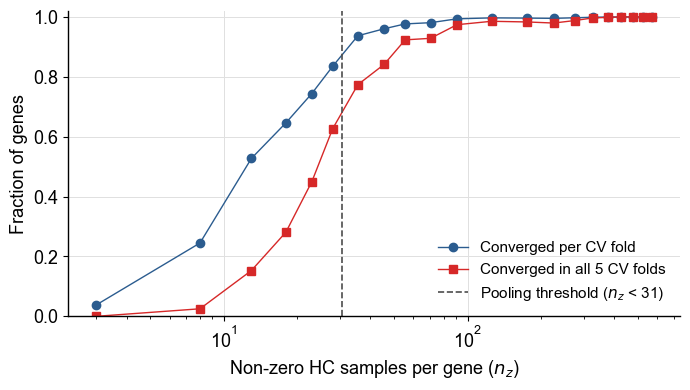

Figure S1. Individual-fit convergence by n_z: n_z < 31 refitted (pooled in the deployed engine), n_z >= 31 deployed engine + production CV
saved -> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/0_EngineDiagnostics/nz_convergence_combined.csv


,n,full_ok,n_cv,per_fold,all5
bin,,,,,
"(0, 5]",450,0.080,450,0.038,0.000
"(5, 10]",436,0.390,436,0.245,0.025
"(10, 15]",392,0.681,392,0.528,0.153
"(15, 20]",338,0.769,338,0.646,0.281
"(20, 25]",280,0.843,280,0.744,0.450
"(25, 30]",284,0.894,284,0.835,0.627
"(30, 40]",488,0.906,442,0.937,0.774
"(40, 50]",411,0.937,385,0.961,0.842
"(50, 60]",370,0.954,353,0.977,0.924


In [14]:
EDGES = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 592]
FOLD_COLS = [f"fold{k}_ok" for k in range(5)]
COMB = config.ENGINE_DIAG_DIR / "nz_convergence_combined.csv"

if COMB.exists():
    comb = pd.read_csv(COMB)
else:
    lo = pd.read_csv(config.ENGINE_DIAG_DIR / "low_nz_convergence.csv")
    low = lo.loc[lo.nz < config.NZ_A_MAX, ["gene", "nz", "full_ok"] + FOLD_COLS].assign(source="n_z experiment")
    summ = pd.read_csv(config.ENGINE_DIR / "training_summary.csv", usecols=["gene", "nz", "route", "ok"])
    summ = summ[(summ.nz >= config.NZ_A_MAX) & (summ.route != "pool")]
    folds = pd.read_csv(config.CV_DIR / "fold_stats.csv").pivot(index="gene", columns="fold", values="ok")
    folds.columns = [f"fold{k}_ok" for k in folds.columns]
    high = summ.rename(columns={"ok": "full_ok"}).drop(columns="route").merge(folds, on="gene", how="left").assign(source="production CV")
    comb = pd.concat([low, high], ignore_index=True)
    comb["n_fold_ok"] = comb[FOLD_COLS].sum(axis=1, min_count=1)
    comb.to_csv(COMB, index=False)

comb["bin"] = pd.cut(comb.nz, EDGES)
has_cv = comb.n_fold_ok.notna()
by = comb.groupby("bin", observed=True).agg(n=("gene", "size"), full_ok=("full_ok", "mean"))
by["n_cv"] = comb[has_cv].groupby("bin", observed=True).size()
by["per_fold"] = comb[has_cv].groupby("bin", observed=True)[FOLD_COLS].apply(lambda d: d.astype(float).values.mean())
by["all5"] = comb[has_cv].groupby("bin", observed=True).n_fold_ok.apply(lambda s: (s == 5).mean())
by["x"] = [(b.left + 1 + b.right) / 2 for b in by.index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by.x, by.per_fold, marker="o", color=BLUE, label="Converged per CV fold")
ax.plot(by.x, by.all5, marker="s", color=RED, label="Converged in all 5 CV folds")
ax.axvline(config.NZ_A_MAX - 0.5, color="0.3", ls="--", lw=1.2, label=r"Pooling threshold ($n_z$ < " + f"{config.NZ_A_MAX})")
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_xlabel(r"Non-zero HC samples per gene ($n_z$)"); ax.set_ylabel("Fraction of genes")
ax.legend(**LEG, loc="lower right"); grid_on(ax)
plt.tight_layout()
plt.savefig(FIG / "figS1_low_nz_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure S1. Individual-fit convergence by n_z: n_z < {config.NZ_A_MAX} refitted (pooled in the deployed engine), n_z >= {config.NZ_A_MAX} deployed engine + production CV")
print(f"saved -> {COMB}")
display(by.drop(columns="x").round(3))